# 05 · Gradient Boosting: Tuning, Training and Offline Evaluation
Course phases **8B (tuning)**, **8C (training)**, **9 (offline evaluation)**

**Builds on:** all previous notebooks (data, preprocessing, features, baselines, chosen C). 
**Files produced:** `src/fdp/boosting.py`, `reports/05_boosting_evaluation.json`, `reports/figures/05_*.png`.

| Section | Phase |
|---|---|
| A · How gradient boosting works | 8 – theory |
| B · Honest tuning with rolling months | 8B |
| C · Final training | 8C |
| D · The final exam on the test months (used **once**) | 9 |
| E · What drives the model, and where it fails | 9 |

⏱️ Full run ≈ 20–30 min on a Colab CPU (the tuning search). Tick `QUICK_RUN` in the setup cell for a ~5 min check.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In Colab, clone this project and install its requirements. Locally, use this checkout.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown Quick mode reduces training iterations; use False for the final report.

import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    project = Path("/content/T107_Flight_Delay_Prediction")
    if not (project / ".git").is_dir():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, str(project)], check=True)
    os.chdir(project)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    here = Path.cwd().resolve()
    project = next((p for p in (here, *here.parents) if (p / "src/fdp/config.py").is_file()), None)
    if project is None:
        raise RuntimeError("Open this notebook from the project root or its notebooks folder.")
    os.chdir(project)
ROOT = Path.cwd()
for folder in ["data/raw", "data/processed", "reports/figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))

import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
print("Working directory:", ROOT, "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /Users/shaikjunaidsami/Desktop/T107_Flight_Delay_Prediction | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features, fdp.preprocess as prep, fdp.metrics as metrics
import fdp.baselines as baselines
from sklearn.metrics import average_precision_score as ap
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
S = data.split(X)
y = {k: v["delayed"].astype(int).to_numpy() for k, v in S.items()}
try:
    BEST_C = json.load(open(ROOT / "reports/04_model_selection.json"))["best_C"]
except FileNotFoundError:
    BEST_C = 0.001
print("Logistic regression C from notebook 04:", BEST_C)

Logistic regression C from notebook 04: 0.001


---
## A · How gradient boosting works
Boosting builds an **additive model** $F(x) = F_0 + \eta\,f_1(x) + \eta\,f_2(x) + \dots$ from small trees $f_m$, where $\eta$ is the learning rate.

For yes/no labels the loss is log loss. Its **negative gradient** with respect to the current prediction $F(x_i)$ is simply $r_i = y_i - p_i$, the "residual" between the label and the predicted probability. Each round:
1. compute $p_i = \sigma(F(x_i))$ and $r_i = y_i - p_i$;
2. fit a small regression tree to $r$ (it groups flights that need a similar correction);
3. set each leaf's value with one Newton step, $\sum r / \sum p(1-p)$;
4. add $\eta \times$ the tree to $F$.

It is the gradient descent of notebook 04, but the step is a **tree** in function space instead of a change of weights. Two dials matter most: the **learning rate** $\eta$ (small = careful steps, needs more trees) and **tree depth** (deeper = more interactions, more risk of over-fitting).

**Bagging vs boosting:** a random forest averages deep, independent trees to cut *variance*. Boosting adds shallow trees one after another, each fixing what is left, to cut *bias*; the learning rate and early stopping keep it from over-fitting.

In [3]:
%%writefile src/fdp/boosting.py
"""Phase 8 gradient boosting with XGBoost: input format, honest rolling-month scoring and
Platt calibration. The matching %%writefile cell in notebook 05 is the source of truth."""
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score


def as_xgb_frame(X, numeric, categorical, categories):
    """Numeric columns as float (NaN allowed: XGBoost learns where missing values go) and
    categoricals as pandas 'category' with a FIXED category list, so codes match across splits."""
    out = X[list(numeric)].astype(float).copy()
    for c in categorical:
        out[c] = pd.Categorical(X[c].astype(str), categories=categories[c])
    return out


def new_xgb(params, n_trees, early_stopping_rounds=None, seed=42):
    """An XGBClassifier with our fixed settings plus the hyper-parameters in `params`."""
    return xgb.XGBClassifier(n_estimators=n_trees, early_stopping_rounds=early_stopping_rounds,
                             objective="binary:logistic", eval_metric="aucpr", tree_method="hist",
                             enable_categorical=True, max_cat_to_onehot=1,
                             random_state=seed, n_jobs=-1, **params)


def rolling_eval(Xf, y, month, params, months=(7, 8, 9), lr_logits=None, seed=42):
    """Honest rolling-month PR AUC for one XGBoost configuration.

    For each scored month m:
      1. train on months before m-1 and early-stop on month m-1 (this picks the number of trees),
      2. refit on ALL months before m with that number of trees,
      3. score month m, which played no part in steps 1-2.
    (Early-stopping on month m and then scoring month m would be optimistic: the stopping rule
    would already have seen the answers.)

    lr_logits: optional {k: logistic-regression logits for every row, from a model fitted on
    months < k}. If given, XGBoost starts each row at that logit (base_margin) and the trees
    only learn corrections on top of logistic regression (the hybrid model).
    """
    scores, trees = [], []
    for m in months:
        inner = month < m - 1    # training rows for step 1
        stop = month == m - 1    # early-stopping month
        full = month < m         # training rows for step 2
        test = month == m        # scored month

        if lr_logits is None:
            start_inner = start_stop = start_full = start_test = None
        else:
            start_inner, start_stop = lr_logits[m - 1][inner], lr_logits[m - 1][stop]
            start_full, start_test = lr_logits[m][full], lr_logits[m][test]

        # 1. early stopping on month m-1 picks the number of trees
        model = new_xgb(params, 3000, early_stopping_rounds=100, seed=seed)
        model.fit(Xf[inner], y[inner], base_margin=start_inner,
                  eval_set=[(Xf[stop], y[stop])], base_margin_eval_set=[start_stop], verbose=False)
        n_trees = model.best_iteration + 1

        # 2. refit on all earlier months with that many trees, 3. score month m
        final = new_xgb(params, n_trees, seed=seed).fit(Xf[full], y[full], base_margin=start_full)
        p = final.predict_proba(Xf[test], base_margin=start_test)[:, 1]
        scores.append(float(average_precision_score(y[test], p)))
        trees.append(int(n_trees))
    return scores, trees


def logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def fit_platt(p, y):
    """Platt scaling: a one-feature logistic regression on logit(p), fitted on a held-out month."""
    return LogisticRegression(C=1e6).fit(logit(p).reshape(-1, 1), y)


def apply_platt(platt, p):
    return platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]


Overwriting src/fdp/boosting.py


---
## B · Phase 8B — Tuning, honestly
We tune with **rolling months** (July, August, September), the same months notebook 04 used, so the comparison with logistic regression is fair.

**A trap we found while building this.** XGBoost's early stopping picks the number of trees by watching a validation set. If we early-stop on September and then *report* September's score, the stopping rule has already seen September's answers, so the score is optimistic. The cell below measures this on one configuration.

**Our protocol (`boosting.rolling_eval`) for each month m:** train on months before m−1, early-stop on m−1, refit on all months before m with that many trees, then score m. Month m plays no part in any choice.

In [4]:
import fdp.boosting as boosting; importlib.reload(boosting)
lab = X[X["delayed"].notna() & (X["date"] >= config.SPLITS["train"][0]) & (X["date"] <= config.SPLITS["valid"][1])].reset_index(drop=True)
ylab = lab["delayed"].astype(int).to_numpy()
month = lab["date"].dt.month.to_numpy()
CATS = {c: sorted(X[c].astype(str).unique()) for c in CAT}       # category list (no label information)
Xf = boosting.as_xgb_frame(lab, NUM, CAT, CATS)

demo = dict(learning_rate=0.05, max_depth=3, min_child_weight=200, subsample=0.7, colsample_bytree=0.5, reg_lambda=10)
# The shortcut: early-stop on month m, then report month m's score
optimistic = []
for m in config.CV_MONTHS:
    tr, va = month < m, month == m
    model = boosting.new_xgb(demo, 3000, early_stopping_rounds=100, seed=config.SEED)
    model.fit(Xf[tr], ylab[tr], eval_set=[(Xf[va], ylab[va])], verbose=False)
    optimistic.append(ap(ylab[va], model.predict_proba(Xf[va])[:, 1]))
# Our protocol: early-stop on month m-1, refit, then score month m
honest, honest_trees = boosting.rolling_eval(Xf, ylab, month, demo, config.CV_MONTHS, seed=config.SEED)
trap = pd.DataFrame({"early-stop on the scored month (optimistic)": optimistic, "our protocol (honest)": honest},
                    index=["Jul", "Aug", "Sep"]).round(4)
trap.loc["mean"] = trap.mean().round(4)
trap

,early-stop on the scored month (optimistic),our protocol (honest)
Jul,0.5709,0.5449
Aug,0.3923,0.3757
Sep,0.2420,0.2246
mean,0.4017,0.3817


The optimistic column is higher on the mean: part of that score came from letting the stopping rule look at the answers. Every number below uses the honest protocol.

In [5]:
# Logistic regression fitted on all months before k, for k = 6..9. Its logits are used twice:
#  - scored on month k (k = 7, 8, 9): the rolling score to beat (no early stopping needed),
#  - as the starting point of the hybrid model further down.
lr_logits = {}
for k in [6, 7, 8, 9]:
    lr = baselines.logistic_regression(NUM, CAT, BEST_C).fit(lab[month < k], ylab[month < k])
    lr_logits[k] = lr.decision_function(lab)
lr_scores = [ap(ylab[month == m], lr_logits[m][month == m]) for m in config.CV_MONTHS]
print("Logistic regression rolling PR AUC:", [round(s, 4) for s in lr_scores], "mean", round(float(np.mean(lr_scores)), 4))

Logistic regression rolling PR AUC: [0.5565, 0.4055, 0.2655] mean 0.4092


In [6]:
#@title 🎛️ Random search over XGBoost hyper-parameters { display-mode: "form" }
N_ITER = 8  #@param {type:"slider", min:2, max:30, step:1}
if QUICK_RUN:
    N_ITER = 2
import itertools
GRID = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4, 6],
    "min_child_weight": [50, 200, 500],
    "subsample": [0.7, 0.9],
    "colsample_bytree": [0.5, 0.8],
    "reg_lambda": [1, 10],
}
all_configs = list(itertools.product(*GRID.values()))          # every combination of the grid
picks = np.random.default_rng(config.SEED).choice(len(all_configs), size=N_ITER, replace=False)
rows = []
for i, pick in enumerate(picks):
    params = dict(zip(GRID, all_configs[pick]))
    scores, trees = boosting.rolling_eval(Xf, ylab, month, params, config.CV_MONTHS, seed=config.SEED)
    rows.append({**params, "mean_pr_auc": float(np.mean(scores)), "fold_pr_auc": [round(s, 4) for s in scores], "trees_per_fold": trees})
    print(f"[{i + 1}/{N_ITER}] {params} -> folds {rows[-1]['fold_pr_auc']} mean {rows[-1]['mean_pr_auc']:.4f} trees {trees}", flush=True)
search = pd.DataFrame(rows).sort_values("mean_pr_auc", ascending=False).reset_index(drop=True)
BEST = {k: search.loc[0, k] for k in GRID}
BEST = {k: (int(v) if k in ("max_depth", "min_child_weight") else float(v)) for k, v in BEST.items()}
print("best configuration:", BEST)
search

[1/8] {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 50, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 1} -> folds [0.5484, 0.3909, 0.219] mean 0.3861 trees [40, 110, 13]


[2/8] {'learning_rate': 0.1, 'max_depth': 2, 'min_child_weight': 200, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 1} -> folds [0.5369, 0.3893, 0.2234] mean 0.3832 trees [21, 112, 34]


[3/8] {'learning_rate': 0.1, 'max_depth': 4, 'min_child_weight': 50, 'subsample': 0.9, 'colsample_bytree': 0.5, 'reg_lambda': 10} -> folds [0.5512, 0.382, 0.1947] mean 0.3759 trees [11, 267, 14]


[4/8] {'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 500, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 10} -> folds [0.5549, 0.3623, 0.2289] mean 0.3820 trees [18, 211, 14]


[5/8] {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 50, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_lambda': 10} -> folds [0.5492, 0.3846, 0.2158] mean 0.3832 trees [56, 523, 103]


[6/8] {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 50, 'subsample': 0.9, 'colsample_bytree': 0.5, 'reg_lambda': 1} -> folds [0.5498, 0.3821, 0.2163] mean 0.3827 trees [11, 982, 14]


[7/8] {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 50, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 10} -> folds [0.5455, 0.3888, 0.2205] mean 0.3849 trees [40, 113, 13]


[8/8] {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 50, 'subsample': 0.7, 'colsample_bytree': 0.8, 'reg_lambda': 1} -> folds [0.5547, 0.38, 0.2024] mean 0.3791 trees [48, 335, 40]


best configuration: {'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 50, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 1.0}


,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,mean_pr_auc,fold_pr_auc,trees_per_fold
0,0.03,3,50,0.7,0.5,1,0.386084,"[0.5484, 0.3909, 0.219]","[40, 110, 13]"
1,0.03,3,50,0.7,0.5,10,0.384935,"[0.5455, 0.3888, 0.2205]","[40, 113, 13]"
2,0.05,3,50,0.7,0.8,10,0.383189,"[0.5492, 0.3846, 0.2158]","[56, 523, 103]"
3,0.10,2,200,0.7,0.5,1,0.383162,"[0.5369, 0.3893, 0.2234]","[21, 112, 34]"
4,0.05,3,50,0.9,0.5,1,0.382707,"[0.5498, 0.3821, 0.2163]","[11, 982, 14]"
5,0.05,6,500,0.7,0.5,10,0.382045,"[0.5549, 0.3623, 0.2289]","[18, 211, 14]"
6,0.10,3,50,0.7,0.8,1,0.379061,"[0.5547, 0.38, 0.2024]","[48, 335, 40]"
7,0.10,4,50,0.9,0.5,10,0.375945,"[0.5512, 0.382, 0.1947]","[11, 267, 14]"


**What the search shows (read the table):**
* The configurations are **close to each other**: tuning moves the mean score only a little, and all of them stay **below logistic regression's** rolling score printed above.
* **Shallow trees** (depth 2–3) fill most of the top places. The depth-6 configuration has the best July score but the worst August score, so its extra interactions do not carry over from one month to the next.
* The **tree count chosen by early stopping varies a lot between folds** (look at `trees_per_fold`). How much non-linear structure carries over from one month to the next is not stable, which is exactly where boosting's advantage should come from.

### A justified hybrid: boosting that starts from logistic regression
Logistic regression captures the main, stable trends; boosting adds interactions. Gradient boosting can **start from any initial prediction**: XGBoost's `base_margin` lets us start each flight at logistic regression's logit, so the trees only learn **corrections** on top of the linear model. Early stopping then decides how much correction transfers to a new month (zero trees = plain logistic regression). It is scored with the same honest protocol.

In [7]:
hybrid_scores, hybrid_trees = boosting.rolling_eval(Xf, ylab, month, BEST, config.CV_MONTHS, lr_logits=lr_logits, seed=config.SEED)
cv_compare = pd.DataFrame({
    "Logistic regression": lr_scores,
    "Gradient boosting (tuned)": search.loc[0, "fold_pr_auc"],
    "Hybrid: boosting from LR": hybrid_scores}, index=["Jul", "Aug", "Sep"]).round(4)
cv_compare.loc["mean"] = cv_compare.mean().round(4)
print("trees per fold - boosting:", search.loc[0, "trees_per_fold"], "| hybrid:", hybrid_trees)
cv_compare

trees per fold - boosting: [40, 110, 13] | hybrid: [16, 1219, 15]


,Logistic regression,Gradient boosting (tuned),Hybrid: boosting from LR
Jul,0.5565,0.5484,0.5594
Aug,0.4055,0.3909,0.3908
Sep,0.2655,0.2190,0.2679
mean,0.4092,0.3861,0.4060


This table is the **model-selection evidence** for the final exam: all three are evaluated on the test months below, and the table tells us in advance which one *should* win. We report the test result whichever way it falls.

---
## C · Phase 8C — Final training
* **Number of trees = median of the counts chosen in the three rolling folds.** One month is not enough: September alone (an unusually calm month) would stop after only a handful of trees, which we print below for comparison. The median of three folds is a steadier choice, and it is still made **before** looking at the test months.
* **Refit** on Jan 15 – Sep 30 with that many trees, so the model sees the most recent month.
* Logistic regression (C from notebook 04) and the hybrid are refitted on the same rows.
* **Calibration (Platt) on October**, a month no model has seen, so the probabilities can be used for the flag list.

In [8]:
fit_rows = pd.concat([S["train"], S["valid"]])
y_fit = fit_rows["delayed"].astype(int).to_numpy()
F = {k: boosting.as_xgb_frame(v, NUM, CAT, CATS) for k, v in S.items()}
F_fit = boosting.as_xgb_frame(fit_rows, NUM, CAT, CATS)

# For comparison only: how many trees would early stopping on September alone keep?
stopper = boosting.new_xgb(BEST, 3000, early_stopping_rounds=100, seed=config.SEED)
stopper.fit(F["train"], y["train"], eval_set=[(F["valid"], y["valid"])], verbose=False)
SEPT_ONLY_TREES = int(stopper.best_iteration + 1)

# Final boosting model: median tree count of the Jul/Aug/Sep folds, refitted on Jan 15 - Sep 30
N_TREES = int(np.median(search.loc[0, "trees_per_fold"]))
gbm = boosting.new_xgb(BEST, N_TREES, seed=config.SEED).fit(F_fit, y_fit)

# Logistic regression (C from notebook 04) and the hybrid, refitted on the same rows
lr_final = baselines.logistic_regression(NUM, CAT, BEST_C).fit(fit_rows, y_fit)
N_TREES_H = int(np.median(hybrid_trees))
hybrid = boosting.new_xgb(BEST, N_TREES_H, seed=config.SEED).fit(F_fit, y_fit, base_margin=lr_final.decision_function(fit_rows))

def predict_all(part):
    return {"Logistic regression": lr_final.predict_proba(S[part])[:, 1],
            "Gradient boosting": gbm.predict_proba(F[part])[:, 1],
            "Hybrid (boosting from LR)": hybrid.predict_proba(F[part], base_margin=lr_final.decision_function(S[part]))[:, 1]}
P_cal, P_test = predict_all("calib"), predict_all("test")
platt = {name: boosting.fit_platt(P_cal[name], y["calib"]) for name in P_cal}   # Platt scaling fitted on October
print(f"trees per fold (boosting): {search.loc[0, 'trees_per_fold']} -> median {N_TREES}  (September alone would pick {SEPT_ONLY_TREES})")
print(f"trees per fold (hybrid)  : {hybrid_trees} -> median {N_TREES_H}")

trees per fold (boosting): [40, 110, 13] -> median 40  (September alone would pick 1)
trees per fold (hybrid)  : [16, 1219, 15] -> median 16


---
## D · Phase 9 — The final exam (test = November–December, used once)
Everything above was decided without the test months. Now each model scores the test set once. Baselines from notebook 04 are included.

In [9]:
yt, dates_t = y["test"], S["test"]["date"]
rows, cal_probs = [], {}
cands = {"Majority class": np.full(len(yt), y["train"].mean()), "Rule: flight's 28-day delay rate": S["test"]["h_flight_28d_rate"].to_numpy()}
for name, p in cands.items():
    e = metrics.evaluate(yt, p); rows.append({"model": name, **e, "ci_low": np.nan, "ci_high": np.nan, "ece_after_platt": np.nan})
for name, p in P_test.items():
    pc = boosting.apply_platt(platt[name], p); cal_probs[name] = pc
    e = metrics.evaluate(yt, p)
    lo, hi = metrics.day_block_bootstrap(yt, p, dates_t, n_boot=50 if QUICK_RUN else 200)
    rows.append({"model": name, **e, "ci_low": lo, "ci_high": hi, "ece_after_platt": metrics.ece(yt, pc)})
test_table = pd.DataFrame(rows).set_index("model")[["pr_auc", "ci_low", "ci_high", "roc_auc", "lift", "brier", "ece", "ece_after_platt"]].round(4)
test_table

,pr_auc,ci_low,ci_high,roc_auc,lift,brier,ece,ece_after_platt
model,,,,,,,,
Majority class,0.2583,NaN,NaN,0.5000,1.0000,0.1917,0.0098,NaN
Rule: flight's 28-day delay rate,0.3692,NaN,NaN,0.6382,1.4293,0.1843,0.0360,NaN
Logistic regression,0.4032,0.3512,0.4585,0.6701,1.5609,0.1792,0.0289,0.0347
Gradient boosting,0.3903,0.3357,0.4508,0.6539,1.5112,0.1820,0.0339,0.0234
Hybrid (boosting from LR),0.4033,0.3523,0.4575,0.6697,1.5614,0.1793,0.0284,0.0321


**How to read it**
* **PR AUC** with a **95% day-block confidence interval**: if two models' intervals overlap heavily, the difference is not reliable.
* **Lift** = PR AUC ÷ base rate (0.258 here): how many times better than random ranking.
* **ECE** before and after Platt scaling: does calibration make the probabilities more honest?

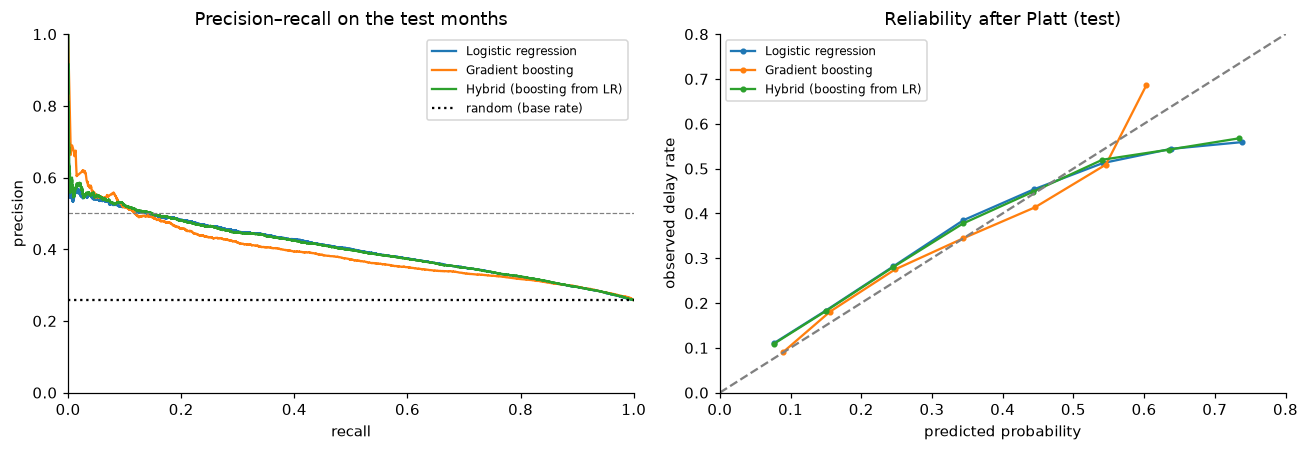

In [10]:
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, p in P_test.items():
    pr, rc, _ = precision_recall_curve(yt, p); ax[0].plot(rc, pr, label=name)
ax[0].axhline(yt.mean(), ls=":", color="black", label="random (base rate)"); ax[0].axhline(0.5, ls="--", color="grey", lw=.8)
ax[0].set(title="Precision–recall on the test months", xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1)); ax[0].legend(fontsize=8)
for name, p in cal_probs.items():
    bins = np.minimum((p * 10).astype(int), 9)
    xs = [p[bins == b].mean() for b in range(10) if (bins == b).sum() > 100]
    ys_ = [yt[bins == b].mean() for b in range(10) if (bins == b).sum() > 100]
    ax[1].plot(xs, ys_, "o-", ms=3, label=name)
ax[1].plot([0, 1], [0, 1], "--", color="grey"); ax[1].set(title="Reliability after Platt (test)", xlabel="predicted probability", ylabel="observed delay rate", xlim=(0, .8), ylim=(0, .8)); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig("reports/figures/05_test_pr_reliability.png"); plt.show()

### Business metric mapping (worksheet Phase 9)
A metric only matters if it maps to an operational result. Two ways to set the flag threshold:
* **(a) October threshold:** pick the score cut-off that gave precision ≥ 0.5 in October.
* **(b) Probability rule:** flag when the calibrated probability is ≥ 0.5.

Then, **per 1,000 test flights**: how many are flagged, how many of those are really delayed, and how many delays a random flag list of the same size would have caught.

In [11]:
biz = []
for name in P_test:
    for rule in ["(a) October threshold", "(b) calibrated p >= 0.5"]:
        if rule.startswith("(a)"):
            thr = metrics.threshold_for_precision(y["calib"], boosting.apply_platt(platt[name], P_cal[name]), 0.5)
        else:
            thr = 0.5
        r = metrics.at_threshold(yt, cal_probs[name], thr)
        flagged = 1000 * r["flag_rate"]
        biz.append({"model": name, "rule": rule, "precision": round(r["precision"], 3), "recall": round(r["recall"], 3),
                    "flagged per 1000": round(flagged, 1), "truly delayed among them": round(flagged * r["precision"], 1),
                    "random list would catch": round(flagged * yt.mean(), 1)})
business = pd.DataFrame(biz); business

,model,rule,precision,recall,flagged per 1000,truly delayed among them,random list would catch
0,Logistic regression,(a) October threshold,0.538,0.055,26.4,14.2,6.8
1,Logistic regression,(b) calibrated p >= 0.5,0.525,0.086,42.6,22.3,11.0
2,Gradient boosting,(a) October threshold,0.547,0.053,25.2,13.8,6.5
3,Gradient boosting,(b) calibrated p >= 0.5,0.517,0.097,48.6,25.2,12.6
4,Hybrid (boosting from LR),(a) October threshold,0.547,0.056,26.2,14.4,6.8
5,Hybrid (boosting from LR),(b) calibrated p >= 0.5,0.529,0.085,41.6,22.0,10.8


**Reading it:** the delay rate rose from 17.6% in October to 25.8% in the test months. That is **drift** in the worksheet's Phase 11 sense: the world the threshold was tuned in has changed. A score cut-off fixed in October (rule a) lands somewhere different in November–December: every model flags only about 25 flights per 1,000 and catches about 5% of the delays. Rule (b), flagging on calibrated probability, keeps precision near 0.5 for every model, which makes it the policy we can explain in advance. In plain words for planners: *out of every 1,000 flights the model hands over a few dozen, about half of which are really late, roughly twice what a random list of the same size would catch.*

---
## E · What drives the model, and where it fails
Feature importance and the group ablation use **October** (not the test set), so they cannot influence the reported test score.

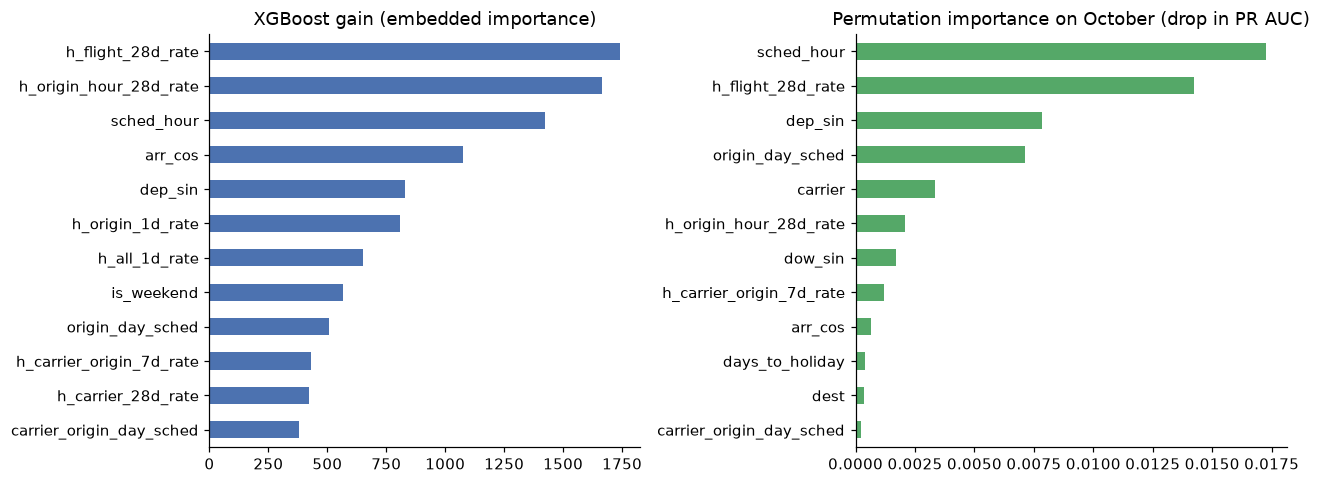

In [12]:
gain = pd.Series(gbm.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
from sklearn.inspection import permutation_importance
cal_rows = S["calib"].sample(min(10000, len(S["calib"])), random_state=config.SEED)
perm = permutation_importance(gbm, boosting.as_xgb_frame(cal_rows, NUM, CAT, CATS), cal_rows["delayed"].astype(int),
                              scoring="average_precision", n_repeats=3 if QUICK_RUN else 5, random_state=config.SEED)
perm_s = pd.Series(perm.importances_mean, index=NUM + CAT).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
gain.head(12)[::-1].plot.barh(ax=ax[0], color="#4C72B0", title="XGBoost gain (embedded importance)")
perm_s.head(12)[::-1].plot.barh(ax=ax[1], color="#55A868", title="Permutation importance on October (drop in PR AUC)")
fig.tight_layout(); fig.savefig("reports/figures/05_importance.png"); plt.show()

**Gain** counts how much each feature improved the training loss inside the trees; it favours features with many possible split points. **Permutation importance** shuffles one feature on unseen October data and measures how much PR AUC drops, which is a more honest view of what the model *relies on*.

In [13]:
abl, cols = [], []
for gname in ["schedule", "calendar", "aircraft", "congestion", "history"]:
    cols = cols + groups[gname]
    m = boosting.new_xgb(BEST, N_TREES, seed=config.SEED).fit(boosting.as_xgb_frame(fit_rows, cols, CAT, CATS), y_fit)
    abl.append({"features": "+ " + gname, "n_numeric": len(cols),
                "october_pr_auc": round(ap(y["calib"], m.predict_proba(boosting.as_xgb_frame(S["calib"], cols, CAT, CATS))[:, 1]), 4)})
ablation = pd.DataFrame(abl); ablation

,features,n_numeric,october_pr_auc
0,+ schedule,7,0.2747
1,+ calendar,11,0.3029
2,+ aircraft,14,0.3035
3,+ congestion,19,0.2911
4,+ history,41,0.2643


**An important finding.** On October, boosting scores *lower* once the history features are added, even though history rates are the top features by gain. Logistic regression did not lose anything from them in notebook 03. Our explanation: a tree splits on **absolute levels** ("flight's 28-day rate > 0.31"), and those levels were learned in a high-delay summer; in calm autumn months every rate is lower, so the learned thresholds sit in the wrong place. A linear model only scales the rate, so a level shift hurts it much less. This is drift again. A natural fix for Phase 2 is to feed history **relative to the overall recent rate** (for example the flight's rate minus the all-flights rate), so the feature means the same thing in every season. We have not measured that fix, so we make no claim about its effect.

In [14]:
err = []
for name, p in P_test.items():
    for label, mask in [("November", S["test"]["date"].dt.month == 11), ("December", S["test"]["date"].dt.month == 12)] + \
                       [(f"origin {o}", S["test"]["origin"] == o) for o in ["EWR", "JFK", "LGA"]]:
        mm = mask.to_numpy()
        err.append({"model": name, "slice": label, "base_rate": round(yt[mm].mean(), 3), "pr_auc": round(ap(yt[mm], p[mm]), 4),
                    "lift": round(ap(yt[mm], p[mm]) / yt[mm].mean(), 2)})
error_table = pd.DataFrame(err).pivot(index="slice", columns="model", values="lift")
error_table

model,Gradient boosting,Hybrid (boosting from LR),Logistic regression
slice,,,
December,1.33,1.36,1.35
November,1.38,1.55,1.58
origin EWR,1.58,1.57,1.57
origin JFK,1.44,1.54,1.54
origin LGA,1.47,1.56,1.56


---
## Conclusions
Read the test table and the rolling-month table together:
1. **Did gradient boosting beat the baselines?** It clearly beats the majority class and the planner's rule. Whether it beats **logistic regression** is the real question; compare the PR AUCs *and* their confidence intervals. Overlapping intervals mean we cannot claim a winner.
2. **Why boosting gains little here:** at 05:00 the strongest information is recent delay history. Trees use it through absolute thresholds that shift between seasons (see the ablation), the interactions they find hold in summer but not in autumn, and the tree counts chosen by early stopping are unstable between months.
3. **The hybrid** starts from logistic regression and adds only the corrections that transfer, so it should never be much worse than logistic regression.
4. **Calibration** matters most for the tree-based models; the October-threshold rule breaks under the base-rate shift.
5. **What would really help:** information known at 05:00 that we do not have (weather forecasts, planned air-traffic programmes) and several years of data for real seasonality. These are Phase 2 / future-work items.

In [15]:
out = {"best_C_lr": BEST_C, "early_stopping_trap": trap.to_dict(), "grid_size": len(all_configs),
       "lr_rolling": lr_scores, "search": search.astype(str).to_dict(orient="records"), "best_params": BEST,
       "cv_compare": cv_compare.to_dict(), "hybrid_trees_per_fold": hybrid_trees, "n_trees_final": N_TREES, "n_trees_hybrid": N_TREES_H, "sept_only_trees": SEPT_ONLY_TREES,
       "test_table": test_table.reset_index().to_dict(orient="records"), "business": business.to_dict(orient="records"),
       "gain_top12": gain.head(12).round(2).to_dict(), "permutation_top12": perm_s.head(12).round(5).to_dict(),
       "ablation_october": ablation.to_dict(orient="records"), "lift_by_slice": error_table.reset_index().to_dict(orient="records"),
       "test_base_rate": float(yt.mean()), "quick_run": QUICK_RUN}
with open("reports/05_boosting_evaluation.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved reports/05_boosting_evaluation.json")

saved reports/05_boosting_evaluation.json


<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **What is the negative gradient of log loss, and why does it matter?** r = y − p. Each tree is fitted to it, so boosting is gradient descent in function space.
2. **Learning rate vs number of trees?** Smaller steps need more trees but usually generalise better; early stopping picks the count.
3. **Why shallow trees won the search.** Deep trees learn summer-specific interactions that fail in September; shallow, regularised trees transfer better.
4. **What was the early-stopping trap?** Stopping on the month you then report lets the stopping rule see the answers; the honest protocol stops on the previous month and refits.
5. **Why rolling months instead of one validation month?** One month (September) has an unusual delay rate; three months give a steadier estimate.
6. **Explain the hybrid.** XGBoost starts from logistic regression's logit (base_margin) and learns only corrections; early stopping decides how many corrections transfer (zero = plain LR).
7. **Did boosting beat logistic regression?** Answer from the test table *with* the confidence intervals; say "no clear winner" if they overlap.
8. **Gain vs permutation importance?** Gain = loss reduction inside training; permutation = drop in held-out PR AUC when a feature is shuffled. Permutation is more honest about what the model relies on.
9. **Why does the October threshold fail on the test months?** The delay rate rose from 17.6% to 25.8% (drift). A fixed score cut-off tuned in one month lands somewhere else; a probability rule adapts better.
10. **Why compute importance and ablation on October, not on test?** The test set is used once; any analysis that could change the model must not look at it.
</details>

In [16]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them.
import glob, zipfile
FILES = [
    'src/fdp/boosting.py',
    'reports/05_boosting_evaluation.json',
    'reports/figures/05_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "05_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 4 files into 05_outputs.zip
   reports/05_boosting_evaluation.json
   reports/figures/05_importance.png
   reports/figures/05_test_pr_reliability.png
   src/fdp/boosting.py
